In [1]:
#202431055_Muhammad Rafi Kurniawan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option('display.max_columns', None)

In [2]:
#202431055_Muhammad Rafi Kurniawan
data = pd.read_csv('marketing_campaign.csv', sep='\t')
print('Ukuran data (baris, kolom):', data.shape)
data.head()

Ukuran data (baris, kolom): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
#202431055_Muhammad Rafi Kurniawan
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
#202431055_Muhammad Rafi Kurniawan
data.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [5]:
#202431055_Muhammad Rafi Kurniawan
print('Jumlah nilai kosong sebelum pembersihan:')
print(data.isna().sum())

Jumlah nilai kosong sebelum pembersihan:
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64


In [6]:
#202431055_Muhammad Rafi Kurniawan
data_bersih = data.copy()

kolom_dibuang = ['ID', 'Z_CostContact', 'Z_Revenue', 'Dt_Customer']
data_bersih = data_bersih.drop(columns=kolom_dibuang)

data_bersih = data_bersih.dropna(subset=['Income'])

data_bersih = data_bersih[(data_bersih['Income'] <= 200000) & (data_bersih['Year_Birth'] >= 1920)]

kolom_belanja = ['MntWines', 'MntFruits', 'MntMeatProducts',
                 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
data_bersih['TotalBelanja'] = data_bersih[kolom_belanja].sum(axis=1)
data_bersih['Usia'] = 2014 - data_bersih['Year_Birth']

data_bersih = data_bersih.reset_index(drop=True)

print('Ukuran data sebelum :', data.shape)
print('Ukuran data sesudah :', data_bersih.shape)
print()
print('Jumlah nilai kosong SESUDAH pembersihan:')
print(data_bersih.isna().sum())

Ukuran data sebelum : (2240, 29)
Ukuran data sesudah : (2212, 27)

Jumlah nilai kosong SESUDAH pembersihan:
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Complain               0
Response               0
TotalBelanja           0
Usia                   0
dtype: int64


In [7]:
#202431055_Muhammad Rafi Kurniawan
fitur = ['Income', 'TotalBelanja']
data_fitur = data_bersih[fitur]

korelasi = data_fitur.corr()
print(korelasi)

               Income  TotalBelanja
Income        1.00000       0.79274
TotalBelanja  0.79274       1.00000


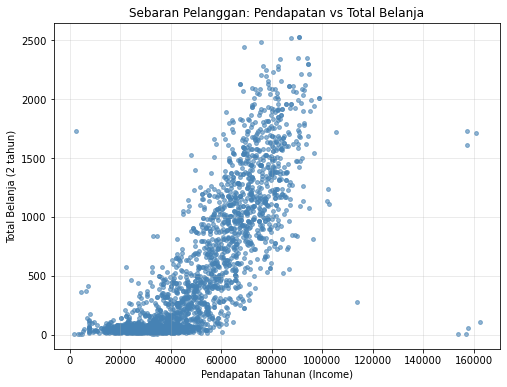

In [8]:
#202431055_Muhammad Rafi Kurniawan
plt.figure(figsize=(8, 6))
plt.scatter(data_bersih['Income'], data_bersih['TotalBelanja'], s=15, alpha=0.6, color='steelblue')
plt.title('Sebaran Pelanggan: Pendapatan vs Total Belanja')
plt.xlabel('Pendapatan Tahunan (Income)')
plt.ylabel('Total Belanja (2 tahun)')
plt.grid(alpha=0.3)
plt.show()

In [9]:
#202431055_Muhammad Rafi Kurniawan
skaler = StandardScaler()
data_terstandar = skaler.fit_transform(data_fitur)

ringkasan_standarisasi = pd.DataFrame({
    'rata_rata': np.round(data_terstandar.mean(axis=0), 6),
    'simpangan_baku': data_terstandar.std(axis=0)
}, index=fitur)
print(ringkasan_standarisasi)

              rata_rata  simpangan_baku
Income             -0.0             1.0
TotalBelanja        0.0             1.0


In [10]:
#202431055_Muhammad Rafi Kurniawan
daftar_k = list(range(1, 11))
daftar_inersia = []

for k in daftar_k:
    model_k = KMeans(n_clusters=k, n_init=10, random_state=0)
    model_k.fit(data_terstandar)
    daftar_inersia.append(model_k.inertia_)

tabel_inersia = pd.DataFrame({'k': daftar_k, 'inertia': daftar_inersia})
tabel_inersia

C:\Users\ASUS ROG\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:881: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


,k,inertia
0,1,4424.000000
1,2,1407.929541
2,3,924.012912
3,4,670.765575
4,5,560.155162
5,6,453.869444
6,7,389.336287
7,8,341.050403
8,9,297.013317
9,10,269.533648


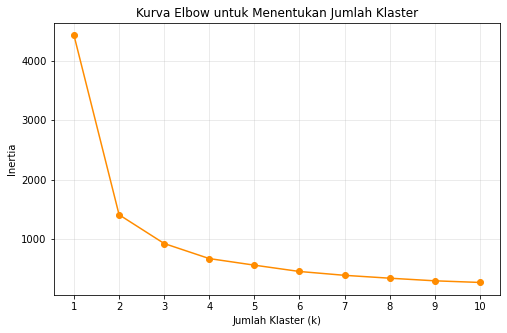

In [11]:
#202431055_Muhammad Rafi Kurniawan
plt.figure(figsize=(8, 5))
plt.plot(daftar_k, daftar_inersia, marker='o', color='darkorange')
plt.title('Kurva Elbow untuk Menentukan Jumlah Klaster')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia')
plt.xticks(daftar_k)
plt.grid(alpha=0.3)
plt.show()

In [12]:
#202431055_Muhammad Rafi Kurniawan
hasil_evaluasi = []

for k in range(2, 7):
    model_k = KMeans(n_clusters=k, n_init=10, random_state=0)
    label_k = model_k.fit_predict(data_terstandar)
    hasil_evaluasi.append({
        'k': k,
        'silhouette_score (makin tinggi makin baik)': silhouette_score(data_terstandar, label_k),
        'DBI (makin rendah makin baik)': davies_bouldin_score(data_terstandar, label_k)
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi).round(4)
tabel_evaluasi

,k,silhouette_score (makin tinggi makin baik),DBI (makin rendah makin baik)
0,2,0.5907,0.5827
1,3,0.4852,0.7345
2,4,0.4368,0.7824
3,5,0.4054,0.8083
4,6,0.4121,0.7391


In [13]:
#202431055_Muhammad Rafi Kurniawan
k_pilihan = 3

model_akhir = KMeans(n_clusters=k_pilihan, n_init=10, random_state=0)
label_klaster = model_akhir.fit_predict(data_terstandar)
data_bersih['Klaster'] = label_klaster

pusat_terstandar = pd.DataFrame(model_akhir.cluster_centers_, columns=fitur)
pusat_terstandar.index.name = 'Klaster'
print('cluster_centers_ (skala terstandarisasi):')
print(pusat_terstandar.round(4))

pusat_asli = pd.DataFrame(skaler.inverse_transform(model_akhir.cluster_centers_), columns=fitur)
pusat_asli.index.name = 'Klaster'
print()
print('cluster_centers_ (skala asli):')
print(pusat_asli.round(2))

print()
print('Jumlah anggota tiap klaster:')
print(data_bersih['Klaster'].value_counts().sort_index())

cluster_centers_ (skala terstandarisasi):
         Income  TotalBelanja
Klaster                      
0        1.2270        1.4733
1       -0.8715       -0.8187
2        0.3960        0.1194

cluster_centers_ (skala asli):
           Income  TotalBelanja
Klaster                        
0        78365.98       1494.74
1        33202.15        114.09
2        60481.76        679.19

Jumlah anggota tiap klaster:
0     520
1    1030
2     662
Name: Klaster, dtype: int64


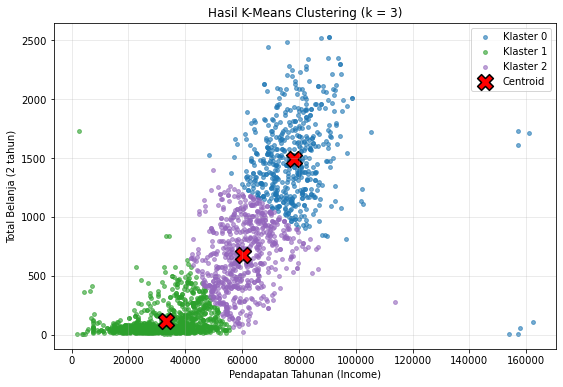

In [14]:
#202431055_Muhammad Rafi Kurniawan
warna_klaster = ['tab:blue', 'tab:green', 'tab:purple', 'tab:orange', 'tab:brown', 'tab:pink']

plt.figure(figsize=(9, 6))
for nomor in range(k_pilihan):
    anggota = data_bersih[data_bersih['Klaster'] == nomor]
    plt.scatter(anggota['Income'], anggota['TotalBelanja'], s=15, alpha=0.6,
                color=warna_klaster[nomor], label=f'Klaster {nomor}')

plt.scatter(pusat_asli['Income'], pusat_asli['TotalBelanja'],
            s=250, c='red', marker='X', edgecolors='black', linewidths=1.5, label='Centroid')

plt.title(f'Hasil K-Means Clustering (k = {k_pilihan})')
plt.xlabel('Pendapatan Tahunan (Income)')
plt.ylabel('Total Belanja (2 tahun)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
#202431055_Muhammad Rafi Kurniawan
kolom_profil = ['Income', 'TotalBelanja', 'Usia', 'Recency', 'NumWebPurchases', 'NumStorePurchases']
profil_klaster = data_bersih.groupby('Klaster')[kolom_profil].mean().round(2)
profil_klaster['Jumlah'] = data_bersih['Klaster'].value_counts().sort_index()
profil_klaster

,Income,TotalBelanja,Usia,Recency,NumWebPurchases,NumStorePurchases,Jumlah
Klaster,,,,,,,
0,78365.98,1494.74,45.70,49.97,5.40,8.36,520
1,33163.69,114.00,42.58,49.03,2.35,3.28,1030
2,60459.19,677.64,48.51,48.26,5.76,7.73,662


In [16]:
#202431055_Muhammad Rafi Kurniawan
urutan_klaster = profil_klaster['TotalBelanja'].sort_values().index.tolist()

daftar_nama = {
    2: ['Pelanggan Hemat', 'Pelanggan Premium'],
    3: ['Pelanggan Hemat', 'Pelanggan Menengah', 'Pelanggan Premium'],
    4: ['Pelanggan Hemat', 'Pelanggan Menengah Bawah', 'Pelanggan Menengah Atas', 'Pelanggan Premium'],
}
nama_urutan = daftar_nama.get(k_pilihan, [f'Segmen {i+1}' for i in range(k_pilihan)])

nama_klaster = {klaster: nama for klaster, nama in zip(urutan_klaster, nama_urutan)}
data_bersih['NamaKlaster'] = data_bersih['Klaster'].map(nama_klaster)

profil_klaster['Nama'] = profil_klaster.index.map(nama_klaster)
profil_klaster

,Income,TotalBelanja,Usia,Recency,NumWebPurchases,NumStorePurchases,Jumlah,Nama
Klaster,,,,,,,,
0,78365.98,1494.74,45.70,49.97,5.40,8.36,520,Pelanggan Premium
1,33163.69,114.00,42.58,49.03,2.35,3.28,1030,Pelanggan Hemat
2,60459.19,677.64,48.51,48.26,5.76,7.73,662,Pelanggan Menengah


In [17]:
#202431055_Muhammad Rafi Kurniawan
skor_silhouette = silhouette_score(data_terstandar, label_klaster)
skor_dbi = davies_bouldin_score(data_terstandar, label_klaster)

print(f'Silhouette score model akhir (k={k_pilihan}) : {skor_silhouette:.4f}  (makin tinggi makin baik)')
print(f'Davies-Bouldin Index model akhir (k={k_pilihan}): {skor_dbi:.4f}  (makin rendah makin baik)')

Silhouette score model akhir (k=3) : 0.4852  (makin tinggi makin baik)
Davies-Bouldin Index model akhir (k=3): 0.7345  (makin rendah makin baik)
